# Understanding the Kalman Filter

A **Kalman filter** estimates the hidden **state** of a system, the set of quantities you want to know, from a stream of noisy measurements.

It can recover quantities that are never measured directly, such as a velocity from position measurements alone, and at each step it reports how sure it is of its estimate.

This notebook builds a filter from scratch on the simplest example: a point moving along a line. The numbers have no units, and no physics is needed. For a first real application, see `01_Ballistics.ipynb`.

In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

import kalman
kalman.set_debug(0)
from kalman.framework.filters import LinearKalmanFilter   # a plain linear Kalman filter


Note: you may need to restart the kernel to use updated packages.


## Step 1 — Describe the System With Four Matrices

The **state** of a point on a line has two numbers, its position and its velocity:

$$\mathbf{x} = \begin{bmatrix} \text{position}\\ \text{velocity}\end{bmatrix}$$

The Kalman filter assumes that the state moves from one step to the next by a matrix multiplication, and that the sensor reads the state through another one:

$$\mathbf{x}_{k} = F\,\mathbf{x}_{k-1} + (\text{process noise}),\qquad
  \mathbf{z}_{k} = H\,\mathbf{x}_{k} + (\text{measurement noise})$$

Four matrices describe the system:

- $F$, the **state-transition matrix**, moves the state forward one time step. For constant velocity: new position = position + velocity × $\Delta t$, and the velocity stays the same.
- $H$, the **measurement matrix**, says what the sensor reads. Here it reads the position only.
- $Q$, the **process-noise covariance**, says how much the real system strays from the $F$ model at each step. A larger $Q$ makes the filter trust the measurements more.
- $R$, the **measurement-noise covariance**, is the variance of the sensor noise. A larger $R$ makes the filter trust the model more.

The filter also needs a starting point: an initial guess `x0` and its covariance `P0`, which says how uncertain that guess is.

## Where F Comes From

Between two measurements the state changes continuously. The position changes at the rate given by the velocity, and the velocity does not change:

$$\dot{\mathbf{x}} = A\,\mathbf{x},\qquad A = \begin{bmatrix} 0 & 1 \\ 0 & 0\end{bmatrix}$$

Solving this equation over one time step $\Delta t$ gives the discrete matrix $F = e^{A\,\Delta t}$. Here $A^2 = 0$, so the exponential series stops after two terms:

$$F = I + A\,\Delta t = \begin{bmatrix}1 & \Delta t\\ 0 & 1\end{bmatrix}$$

The next cell checks this, first symbolically and then with numbers.

In [2]:
from scipy.linalg import expm
from kalman.helpers import symbolic_discretize

dt = 1.0   # time between two steps

A = np.array([[0.0, 1.0],    # d(position)/dt = velocity
              [0.0, 0.0]])   # d(velocity)/dt = 0 (constant velocity)

print("Symbolic F(dt) = exp(A * dt):")
print(symbolic_discretize(A, t="dt"))

F_numeric = expm(A * dt)
print(f"\nNumeric F at dt = {dt}:\n{F_numeric}")

Symbolic F(dt) = exp(A * dt):


Matrix([[1, dt], [0, 1]])

Numeric F at dt = 1.0:
[[1. 1.]
 [0. 1.]]


In [3]:
SIGMA_BAND = 3       # number of standard deviations to show in uncertainty bands

# An empty linear filter: 2 state numbers, 1 measurement, 1 step per second.
kf = LinearKalmanFilter(n=2, m=1, fs=1.0, random_seed=1)

# The four matrices and the initial guess.
kf.F = [[1, dt],     # position += velocity * dt   (dt from the cell above)
        [0,  1]]     # velocity stays constant
kf.H = [[1, 0]]      # we measure position only
kf.Q = [[0.01, 0],   # process noise: position and velocity each stray by a std of 0.1 per step
        [0,    0.01]]
kf.R = [[4.0]]       # measurement noise: sensor std = 2, variance = 4
kf.x0 = [0, 1]       # start: position 0, velocity 1
kf.P0 = [[25, 0],    # initial uncertainty: std 5 on position,
         [0,  4]]    #                      std 2 on velocity

kf.model.print(matrices=True)   # dimensions and the four matrices in one place

KalmanModel @ fs=1.0Hz
    Kalman Model (v2.0)
        Generic model for Kalman-family filters; matrices
        (F/H/…) or override f/h.
    Dimensions Summary:
        State Vector....................................: 2 dims (KalmanModelState<X0, X1>)
        Observation.....................................: 1 dim  (KalmanModelObservable<Z0>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 2x1 dims
        State Covariance (P0)...........................: 2x2 dims
    Matrices:
        F: 2x2 dims
        [[1. 1.]
         [0. 1.]]
        H: 1x2 dims
        [[1. 0.]]
        Q: 2x2 dims
        [[0.01 0.  ]
         [0.   0.01]]
        R: 1x1 dims
        [[4.]]



## Step 2 — Build Three Trajectories: Ideal, True, and Measured

To test a filter we simulate data, in three versions:

- **Ideal**: the trajectory from $F$ alone, with no noise.
- **True**: one actual run, where the process noise ($Q$) pushes the system off the ideal path.
- **Measured**: the true position seen through the sensor noise ($R$).

The filter receives only the measured dots. Its job is to reconstruct the true state behind them.

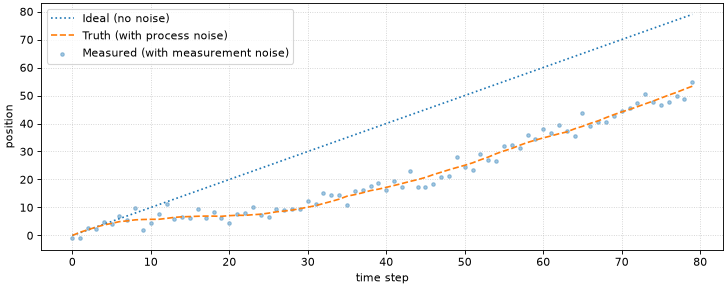

In [4]:
sample = kf.sample(80)                         # 80 steps: true state + measurements
t      = sample.time
true   = np.asarray(sample.xk)                 # the hidden true state
meas   = np.asarray(sample.zk)                 # what the sensor reports
ideal  = np.asarray(kf.model.ideal(duration=80))   # the noise-free reference

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, ideal[:, 0], ':',  label="Ideal (no noise)")
ax.plot(t, true[:, 0],  '--', label="Truth (with process noise)")
ax.scatter(t, meas[:, 0], s=10, alpha=0.4, label="Measured (with measurement noise)")
ax.set_xlabel("time step")
ax.set_ylabel("position")
ax.legend()
ax.grid(True, ls=":", alpha=0.6)
plt.show()

## Step 3 — Predict, Then Correct

At every step the Kalman filter does two things.

1. **Predict.** It moves its estimate one step forward with $F$. Its uncertainty grows by $Q$, because the model is not perfect.
2. **Correct.** It blends the prediction with the new measurement. The weight of the measurement in this blend is the **Kalman gain** $K$: close to 1 when the sensor is more reliable than the prediction, close to 0 when it is noisier. After the correction the uncertainty shrinks.

Along with the estimate, the filter carries its **covariance** $P$, its own measure of uncertainty. The shaded band in the plot is ± 3 standard deviations (the square roots of the diagonal of $P$).

The right panel shows the velocity, which is never measured. The filter recovers it because the position changes at the rate given by the velocity, so a wrong velocity soon shows up as a wrong predicted position.

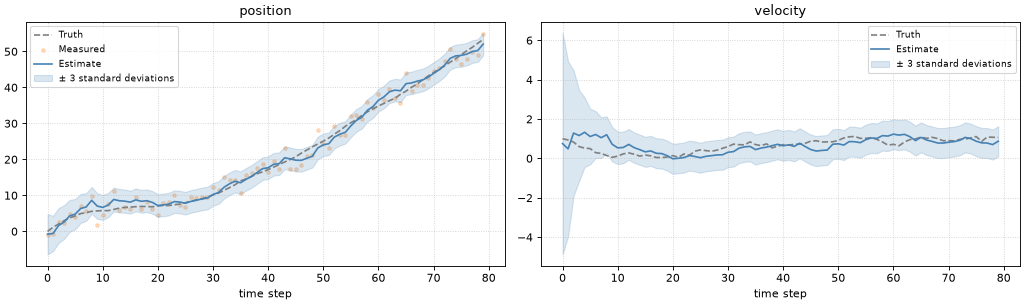

In [5]:
record = kf.filter(sample, reset=True)   # run the forward filter
est = np.asarray(record.xk)              # state estimate at each step
P   = np.asarray(record.Pk)              # covariance (uncertainty) at each step

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (ax, name) in enumerate(zip(axes, ["position", "velocity"])):
    sd = np.sqrt(P[:, i, i])             # standard deviation of this state
    ax.plot(t, true[:, i], '--', color='gray', label='Truth')
    if i == 0:
        ax.scatter(t, meas[:, 0], s=10, alpha=0.25, color='tab:orange', label='Measured')
    ax.plot(t, est[:, i], color='steelblue', label='Estimate')
    ax.fill_between(t, est[:, i] - SIGMA_BAND*sd, est[:, i] + SIGMA_BAND*sd, color='steelblue', alpha=0.2,
                    label=f'± {SIGMA_BAND} standard deviations')
    ax.set_title(name)
    ax.set_xlabel("time step")
    ax.legend(fontsize=8)
    ax.grid(True, ls=':', alpha=0.6)
plt.tight_layout()
plt.show()


## Step 4 — Look Back With the Smoother

At step $k$ the forward filter has seen only the measurements up to $k$. When the whole recording is available, a second pass that runs backward in time lets every estimate use the later measurements too. This is the **Rauch–Tung–Striebel smoother**. It gives better estimates and a narrower uncertainty band, but only after the fact: it cannot run in real time.

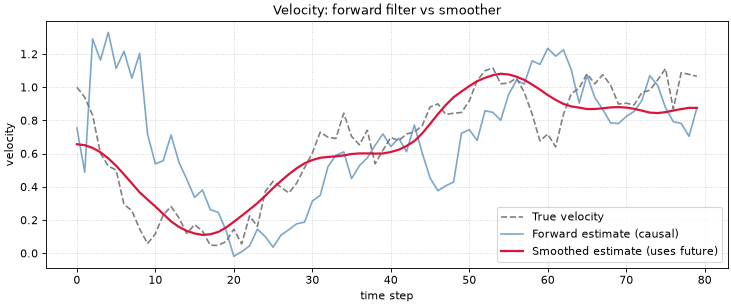

In [6]:
smoothed = kf.backward()                       # the backward (smoother) pass over the same run
smoothed_vel = np.asarray(smoothed.xk)[:, 1]   # smoothed velocity estimate

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, true[:, 1], '--', color='gray',      label='True velocity')
ax.plot(t, est[:, 1],        color='steelblue', alpha=0.7, label='Forward estimate (causal)')
ax.plot(t, smoothed_vel,     color='crimson',   lw=2,      label='Smoothed estimate (uses future)')
ax.set_title("Velocity: forward filter vs smoother")
ax.set_xlabel("time step")
ax.set_ylabel("velocity")
ax.legend()
ax.grid(True, ls=':', alpha=0.6)
plt.show()


## Step 5 — Check That the Filter Is Consistent

A filter is **consistent** when the errors it makes are as large as the uncertainty it claims. The dashboard below shows four checks.

- **Innovation** $\nu$: the measurement minus the measurement the filter predicted. It should scatter around zero and stay inside its ± 3 standard deviation band.
- **Kalman gain**: how strongly a measurement corrects each state. It settles to a constant once the uncertainty stops changing.
- **Normalized Innovation Squared (NIS)**: the innovation squared, divided by the variance $S$ the filter predicted for it. It needs no truth, so it also works on real data.
- **Normalized Estimation Error Squared (NEES)**: the estimation error squared, divided by the covariance $P$ the filter claims. It needs the true state, so it is available only in simulation.

Both normalized checks divide a squared error by its claimed variance, so an honest filter gives 1 per dimension on average. NIS should average to the measurement dimension $m = 1$, and NEES to the state dimension $n = 2$. A much larger value means the filter is over-confident, a much smaller one that it is over-cautious. Single steps scatter widely; only the average over the run counts.

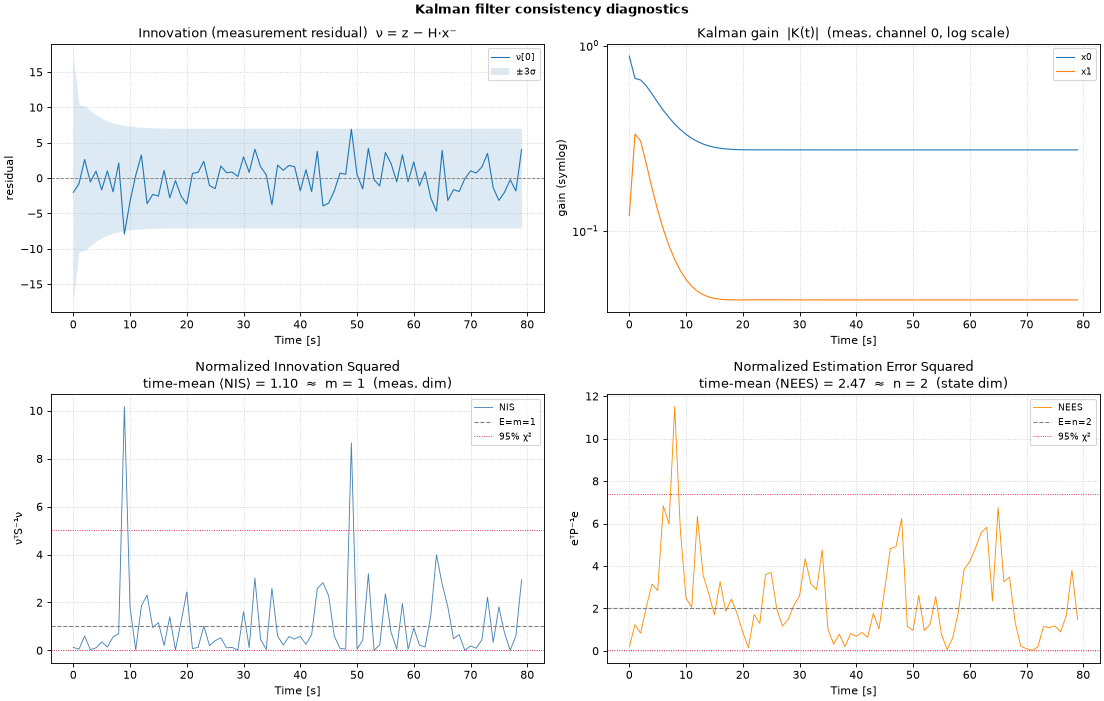

Normalized Innovation Squared,        mean = 1.10   (ideal ≈ m = 1)
Normalized Estimation Error Squared,  mean = 2.47   (ideal ≈ n = 2)


In [7]:
kf.filter(sample, reset=True)            # forward pass (the diagnostics read it)
kf.diagnostics(sample=sample)            # innovation, gain, and the two normalized checks
plt.show()

print(f"Normalized Innovation Squared,        mean = {kf.nis().mean():.2f}   (ideal ≈ m = {kf.m})")
print(f"Normalized Estimation Error Squared,  mean = {kf.nees(sample.xk).mean():.2f}   (ideal ≈ n = {kf.n})")

## Step 6 — Change the System by Changing the Matrices

The filter is only its four matrices, so a different system means different matrices and nothing else.

As an example, add a second sensor that measures the velocity. $H$ gets a second row, $R$ a second entry, and the measurement dimension becomes $m = 2$. Both filters then run on the same simulated trajectory, the first one seeing only the position column, and we compare how far each velocity estimate is from the true velocity.

In [8]:
kf2 = LinearKalmanFilter(
    n=2, m=2, fs=1.0,
    F=[[1, dt], [0, 1]],
    H=[[1, 0],            # sensor 1: position
       [0, 1]],           # sensor 2: velocity (new)
    Q=[[0.01, 0], [0, 0.01]],
    R=[[4.0, 0   ],       # position-sensor variance
       [0,   0.25]],      # velocity-sensor variance (std 0.5)
    x0=[0, 1], P0=[[25, 0], [0, 4]], random_seed=1,
)
sample2 = kf2.sample(80)                       # one trajectory, measured by both sensors
truth2  = np.asarray(sample2.xk)
meas2   = np.asarray(sample2.zk)

record_pos_only    = kf.filter(meas2[:, :1], reset=True)    # position column only
record_two_sensors = kf2.filter(sample2, reset=True)        # position + velocity

def velocity_rmse(record):
    return np.sqrt(np.mean((np.asarray(record.xk)[:, 1] - truth2[:, 1])**2))

print(f"velocity error (RMS) — position sensor only : {velocity_rmse(record_pos_only):.3f}")
print(f"velocity error (RMS) — + velocity sensor    : {velocity_rmse(record_two_sensors):.3f}")

velocity error (RMS) — position sensor only : 0.366
velocity error (RMS) — + velocity sensor    : 0.173


## Step 7 — Use the Same Filter for a New System: a Low-Pass Filter

Nothing in the filter is specific to motion. Take a single slowly drifting value, such as a temperature or a voltage, read by a noisy sensor:

$$x_k = x_{k-1} + w_k,\qquad z_k = x_k + v_k$$

Here $w_k$ is the drift per step, with standard deviation $q$, and $v_k$ is the sensor noise, with standard deviation $r$. So $n=1$, $F=[1]$, $H=[1]$, $Q=[q^2]$, $R=[r^2]$.

After a few steps the gain stops changing, because each predict adds as much uncertainty as each correction removes. Call this steady value $K_\mathrm{ss}$. The correction is then

$$\hat{x}_k=\hat{x}_{k-1}+K_\mathrm{ss}\,(z_k-\hat{x}_{k-1})=(1-K_\mathrm{ss})\,\hat{x}_{k-1}+K_\mathrm{ss}\,z_k$$

where $\hat{x}_k$ is the estimate. This is an **exponential moving average** (EMA): each new estimate keeps a fraction $1-K_\mathrm{ss}$ of the old one and takes a fraction $K_\mathrm{ss}$ of the new measurement. An EMA is the simplest **low-pass filter**: it lets slow changes through and averages fast noise away.

Writing out that balance between predict and correction and solving for the gain gives

$$K_\mathrm{ss}=\dfrac{\sqrt{q^4+4q^2r^2}-q^2}{2r^2}$$

which depends only on the ratio $q/r$. The cell below runs the Kalman filter and the EMA side by side.

steady-state Kalman gain  K_ss = 0.0488


max |Kalman - low-pass| once converged: 4.44e-15


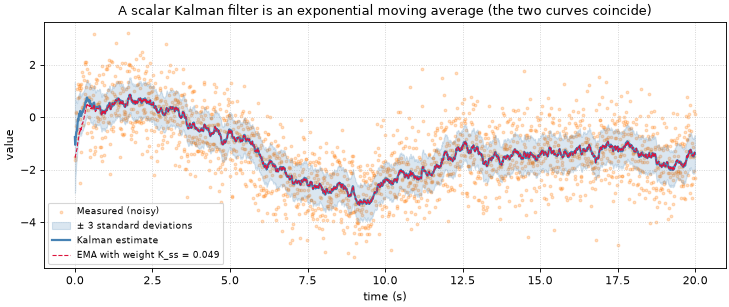

In [9]:
# A one-state model of a drifting value, built from the same four matrices.
drift_std, sensor_std = 0.05, 1.0      # q: drift per step (std), r: sensor noise (std)
lpkf = LinearKalmanFilter(
    n=1, m=1, fs=100.0,                 # one state, one measurement, 100 samples per second
    F=[[1.0]],                          # the value stays put (plus process noise)
    H=[[1.0]],                          # the sensor reads the value directly
    Q=[[drift_std**2]],                 # how fast the true value drifts
    R=[[sensor_std**2]],                # how noisy the sensor is
    x0=[0.0], P0=[[1.0]], random_seed=0,
)
sig = lpkf.sample(20.0)                 # 20 s @ 100 Hz of a drifting signal + noisy measurements
rec = lpkf.filter(sig, reset=True)

# Steady-state Kalman gain (closed form) and the equivalent exponential moving average.
K_ss = (np.sqrt(drift_std**4 + 4*drift_std**2*sensor_std**2) - drift_std**2) / (2*sensor_std**2)
t  = sig.time
z  = np.asarray(sig.zk).ravel()
xk = np.asarray(rec.xk).ravel()
sd = np.sqrt(np.asarray(rec.Pk)[:, 0, 0])

ema = np.empty_like(z)
ema[0] = z[0]
for k in range(1, len(z)):
    ema[k] = (1 - K_ss) * ema[k-1] + K_ss * z[k]     # the steady-state Kalman correction

print(f"steady-state Kalman gain  K_ss = {K_ss:.4f}")
print(f"max |Kalman - low-pass| once converged: {np.max(np.abs(xk[len(z)//2:] - ema[len(z)//2:])):.2e}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(t, z, s=6, alpha=0.25, color="tab:orange", label="Measured (noisy)")
ax.fill_between(t, xk - SIGMA_BAND*sd, xk + SIGMA_BAND*sd, color="steelblue", alpha=0.2,
                label=f"± {SIGMA_BAND} standard deviations")
ax.plot(t, xk,  color="steelblue", lw=2, label="Kalman estimate")
ax.plot(t, ema, color="crimson", lw=1, ls="--", label=f"EMA with weight K_ss = {K_ss:.3f}")
ax.set_xlabel("time (s)")
ax.set_ylabel("value")
ax.legend(fontsize=8)
ax.grid(True, ls=":", alpha=0.6)
ax.set_title("A scalar Kalman filter is an exponential moving average (the two curves coincide)")
plt.show()

### Step 7a — View the Filter in the Frequency Domain

A low-pass filter is described by its **frequency response** $G(f)$: the factor by which it scales a sine wave of frequency $f$. Slow sines pass with $|G| \approx 1$; fast ones are reduced. The **cutoff frequency** is where the power has dropped by half (−3 dB).

What the low-pass removes is $z$ minus its output, with response $1-G$. That is the matching **high-pass filter**, so the two outputs always add up to the measurement.

The ratio $q/r$ sets the cutoff. A large $q$ says the value moves quickly, so the filter follows the data closely: high cutoff, little smoothing. A small $q$ gives a low cutoff and heavy smoothing.

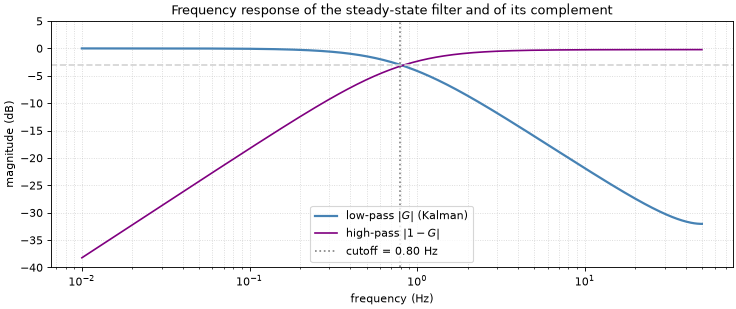

In [10]:
CUTOFF_DB = -3   # the cutoff frequency is where the response has dropped by 3 dB (half the power)

fs = 100.0
freqs = np.logspace(-2, np.log10(fs/2), 400)
w = 2*np.pi*freqs/fs
G = K_ss / (1 - (1 - K_ss)*np.exp(-1j*w))                      # frequency response of the EMA
gain_db = 20*np.log10(np.abs(G))
fc = freqs[np.argmin(np.abs(gain_db - CUTOFF_DB))]             # cutoff frequency at the -3 dB point

fig, ax = plt.subplots(figsize=(11, 4))
ax.semilogx(freqs, gain_db,                                 color="steelblue", lw=2,   label="low-pass $|G|$ (Kalman)")
ax.semilogx(freqs, 20*np.log10(np.abs(1 - G) + 1e-12), color="purple",    lw=1.5, label="high-pass $|1-G|$")
ax.axvline(fc, color="gray", ls=":", label=f"cutoff = {fc:.2f} Hz")
ax.axhline(CUTOFF_DB, color="lightgray", ls="--")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("magnitude (dB)")
ax.set_ylim(-40, 5)
ax.legend()
ax.grid(True, which="both", ls=":", alpha=0.5)
ax.set_title("Frequency response of the steady-state filter and of its complement")
plt.show()

### Step 7b — Confirm the Diagnostics Still Work

The consistency checks of Step 5 do not depend on what the state means. The same `.diagnostics()` call works on this one-state model, and NIS should again average to $m = 1$.

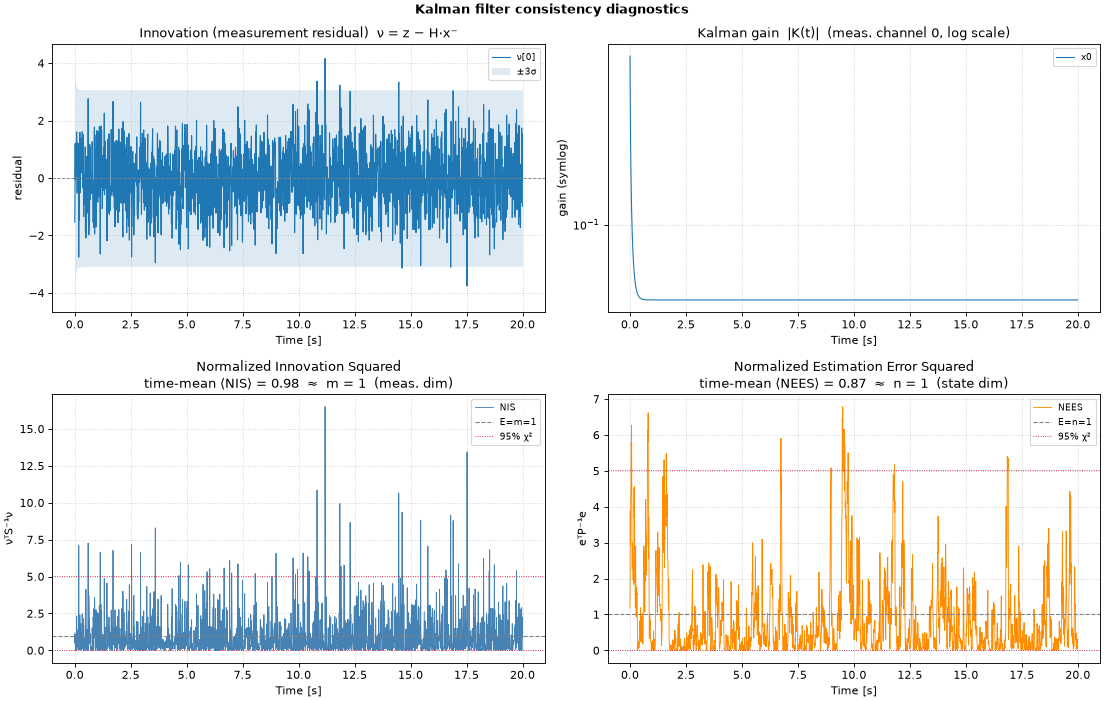

Normalized Innovation Squared, mean = 0.98   (ideal ≈ m = 1)


In [11]:
lpkf.filter(sig, reset=True)
lpkf.diagnostics(sample=sig)          # the same dashboard as in Step 5
plt.show()
print(f"Normalized Innovation Squared, mean = {lpkf.nis().mean():.2f}   (ideal ≈ m = {lpkf.m})")

### Step 7c — Build a High-Pass and a Band-Pass Filter

Other filters follow from the same EMA. Write `lp(z, f_c)` for the EMA with cutoff `f_c`; its smoothing factor is `α = 1 − e^(−2π f_c / f_s)`, with `f_s` the sample rate. Then:

- **Low-pass** = `lp(z, f_c)` keeps what is below `f_c`.
- **High-pass** = `z − lp(z, f_c)` keeps what is above `f_c`.
- **Band-pass** = `lp(z, f_high) − lp(z, f_low)` keeps what lies between the two cutoffs.

The test signal below is the sum of a slow drift (0.3 Hz), a mid tone (5 Hz) and a fast tone (30 Hz) with noise. The three filters separate it into its three parts. The separation is not perfect, because a one-pole filter cuts off gradually.

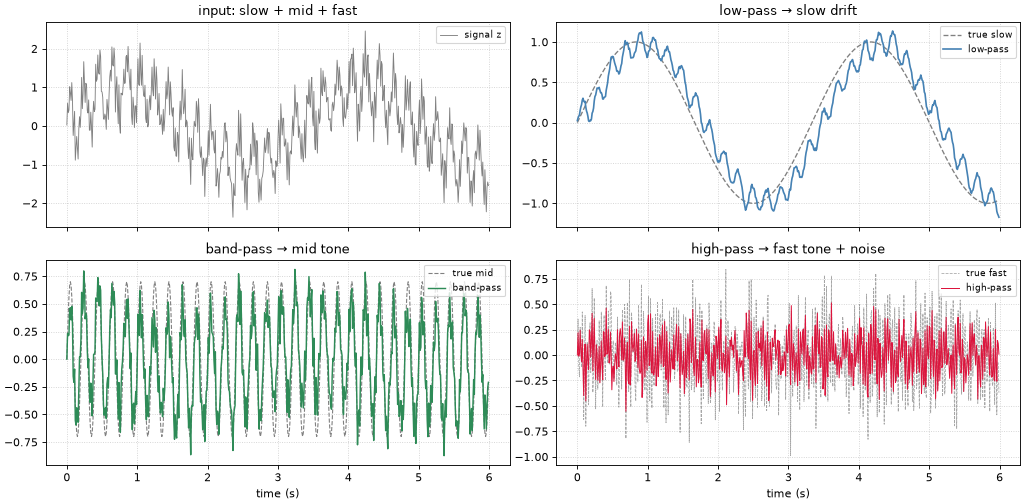

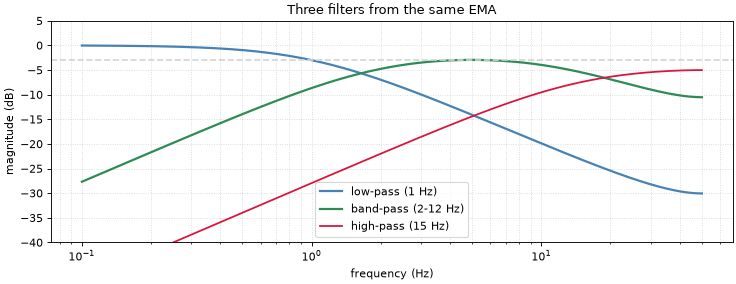

In [12]:
# A 3-band test signal: slow drift + mid tone + fast tone with noise.
fs_band = 100.0
t_band = np.arange(0, 6.0, 1/fs_band)
rng = np.random.default_rng(0)
slow = 1.0*np.sin(2*np.pi*0.3*t_band)                                          # ~0.3 Hz  (low band)
mid  = 0.7*np.sin(2*np.pi*5.0*t_band)                                          # ~5 Hz    (mid band)
fast = 0.4*np.sin(2*np.pi*30.0*t_band) + 0.2*rng.standard_normal(t_band.size)  # ~30 Hz + noise (high band)
signal_band = slow + mid + fast

def ema(x, alpha):                          # first-order low-pass (exponential moving average)
    y = np.empty_like(x)
    acc = x[0]
    for k in range(len(x)):
        acc = (1 - alpha)*acc + alpha*x[k]
        y[k] = acc
    return y

alpha_for = lambda cutoff_hz: 1.0 - np.exp(-2*np.pi*cutoff_hz/fs_band)   # EMA smoothing for a -3 dB cutoff

low_pass  = ema(signal_band, alpha_for(1.0))                                     # keep < ~1 Hz
high_pass = signal_band - ema(signal_band, alpha_for(15.0))                      # keep > ~15 Hz
band_pass = ema(signal_band, alpha_for(12.0)) - ema(signal_band, alpha_for(2.0)) # keep ~2..12 Hz

fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
ax[0, 0].plot(t_band, signal_band, color="gray", lw=0.8, label="signal z")
ax[0, 0].set_title("input: slow + mid + fast")
ax[0, 1].plot(t_band, slow, color="gray", lw=1.2, ls="--", label="true slow")
ax[0, 1].plot(t_band, low_pass, color="steelblue", lw=1.5, label="low-pass")
ax[0, 1].set_title("low-pass → slow drift")
ax[1, 0].plot(t_band, mid, color="gray", lw=1.0, ls="--", label="true mid")
ax[1, 0].plot(t_band, band_pass, color="seagreen", lw=1.3, label="band-pass")
ax[1, 0].set_title("band-pass → mid tone")
ax[1, 1].plot(t_band, fast, color="gray", lw=0.7, ls="--", alpha=0.7, label="true fast")
ax[1, 1].plot(t_band, high_pass, color="crimson", lw=0.9, label="high-pass")
ax[1, 1].set_title("high-pass → fast tone + noise")
for a in ax.ravel():
    a.grid(True, ls=":", alpha=0.6)
    a.legend(fontsize=8, loc="upper right")
for a in ax[1]:
    a.set_xlabel("time (s)")
plt.tight_layout()
plt.show()

# Frequency view: the three filters built from the same EMA.
freqs = np.logspace(-1, np.log10(fs_band/2), 400)
w_band = 2*np.pi*freqs/fs_band
G_ema = lambda cutoff_hz: alpha_for(cutoff_hz) / (1 - (1 - alpha_for(cutoff_hz))*np.exp(-1j*w_band))
G_low, G_high, G_band = G_ema(1.0), 1 - G_ema(15.0), G_ema(12.0) - G_ema(2.0)

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.semilogx(freqs, 20*np.log10(np.abs(G_low)),          color="steelblue", lw=2,   label="low-pass (1 Hz)")
ax.semilogx(freqs, 20*np.log10(np.abs(G_band) + 1e-12), color="seagreen",  lw=2,   label="band-pass (2-12 Hz)")
ax.semilogx(freqs, 20*np.log10(np.abs(G_high) + 1e-12), color="crimson",   lw=1.6, label="high-pass (15 Hz)")
ax.axhline(CUTOFF_DB, color="lightgray", ls="--")
ax.set_ylim(-40, 5)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("magnitude (dB)")
ax.legend()
ax.grid(True, which="both", ls=":", alpha=0.5)
ax.set_title("Three filters from the same EMA")
plt.show()

## Step 8 — Close the Loop With Control

So far the filter only watched: its estimate never acted on the system. A **controller** closes the loop. It reads the latest estimate $\hat{x}$ and outputs a **control signal** $u$ that pushes the system toward a target $x_\text{ref}$.

```
 controller ──u──► system ──z──► filter ──x̂──┐
     ▲                                        │
     └────────────────────────────────────────┘
```

One extra matrix, $B$, says how the control enters the state:

$$\mathbf{x}_{k} = F\,\mathbf{x}_{k-1} + B\,u_{k-1} + (\text{process noise})$$

The filter is given the same $u$, so its prediction accounts for the push. Everything else is unchanged.

Below, the drifting value of Step 7 gets $B = [1]$, so $u$ shifts the value directly. A **proportional controller**, $u = -K_p\,(\hat{x} - x_\text{ref})$, pushes in proportion to the remaining distance and drives the value from 0 to the target 5. With $K_p = 0.5$, each step closes half of the gap the filter sees.

`12_KalmanAI.ipynb` takes control further.

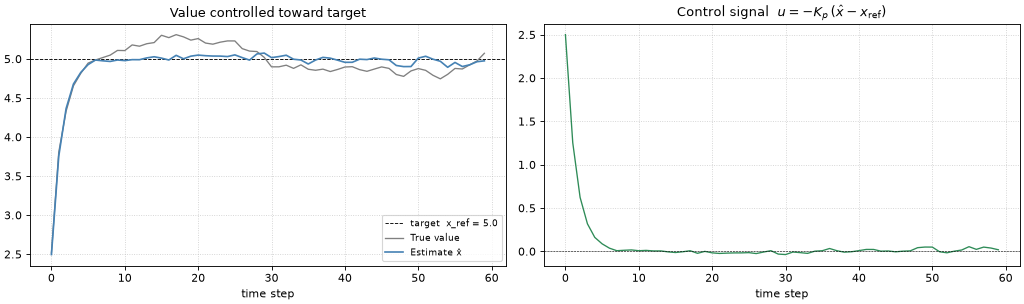

Final true value: 5.07   (target 5.0,  residual = +0.07)


In [13]:
# The drifting value of Step 7, plus B = [1]: x(k) = F·x(k-1) + B·u(k-1) + noise
kfc = LinearKalmanFilter(
    n=1, m=1, fs=1.0,
    F=[[1.0]], H=[[1.0]], B=[[1.0]],           # same as Step 7, plus B
    Q=[[drift_std**2]], R=[[sensor_std**2]],   # same noise parameters as Step 7
    x0=[[0.0]],
)

x_ref = 5.0   # target value
Kp    = 0.5   # proportional gain:  u = -Kp · (x̂ − x_ref)

N = 60
rng_ctrl = np.random.default_rng(42)
x_true_c = np.array([[0.0]])
pos_true, pos_est, u_hist = [], [], []

for k in range(N):
    # controller reads the filter estimate and computes u
    u  = -Kp * (kfc.x[0, 0] - x_ref)
    uk = np.array([[u]])

    # truth: the physical system responds to the actual control u
    x_true_c = np.array([[1.0]]) @ x_true_c + np.array([[1.0]]) @ uk \
               + rng_ctrl.normal(0, drift_std, (1, 1))
    z = np.array([[x_true_c[0, 0] + rng_ctrl.normal(0, sensor_std)]])

    # one filter step, given the measurement and the same u
    kfc.forward(z, uk=uk, reset=(k == 0))

    pos_true.append(x_true_c[0, 0])
    pos_est.append(kfc.x[0, 0])
    u_hist.append(u)

t_steps = np.arange(N)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.axhline(x_ref, color="k", ls="--", lw=0.8, label=f"target  x_ref = {x_ref}")
ax.plot(t_steps, pos_true, color="gray",      lw=1.2, label="True value")
ax.plot(t_steps, pos_est,  color="steelblue", lw=1.5, label="Estimate x̂")
ax.set_title("Value controlled toward target")
ax.set_xlabel("time step")
ax.legend(fontsize=8)
ax.grid(True, ls=":", alpha=0.6)

ax = axes[1]
ax.plot(t_steps, u_hist, color="seagreen", lw=1.2)
ax.axhline(0, color="k", ls="--", lw=0.5)
ax.set_title(r"Control signal  $u = -K_p\,(\hat{x} - x_{\rm ref})$")
ax.set_xlabel("time step")
ax.grid(True, ls=":", alpha=0.6)

plt.tight_layout()
plt.show()
print(f"Final true value: {pos_true[-1]:.2f}   (target {x_ref},  residual = {pos_true[-1]-x_ref:+.2f})")

## Summary and Where to Go Next

| Idea | Step |
|---|---|
| A system is four matrices: $F$, $H$, $Q$, $R$ | 1 |
| Ideal, true and measured data | 2 |
| Predict, correct, the Kalman gain and the uncertainty band | 3 |
| The smoother, which also uses later measurements | 4 |
| Consistency checks: innovation, gain, NIS, NEES | 5 |
| A different system is a different set of matrices | 6 |
| A scalar Kalman filter is a low-pass filter | 7 |
| $B$ and a controller close the loop | 8 |

Everything here was linear. When the dynamics or the sensor are nonlinear, the same predict/correct cycle still applies:

- the **Extended Kalman filter** linearizes the system around the current estimate at each step;
- the **Unscented Kalman filter** pushes a small set of sample points through the nonlinear functions instead;
- the **particle filter** uses many random samples and handles problems that are far from Gaussian.

Where to go next:

- `01_Ballistics.ipynb` tracks a projectile in three dimensions under gravity and air drag.
- `kalman.runtime.signals` holds ready-made versions of the filters of Step 7.
- `12_KalmanAI.ipynb` extends Step 8 to steering a car.